## Import tools

In [1]:
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS #Builds a vector index and searches for similar text.
from langchain_ollama import OllamaEmbeddings, ChatOllama
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import ChatPromptTemplate

C:\Users\User\AppData\Local\Temp\ipykernel_20888\3152606113.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


## 2. Load Documents

In [2]:
urls=[
    "https://langchain-ai.github.io/langgraph/tutorials/introduction/",
    "https://langchain-ai.github.io/langgraph/tutorials/workflows/",
    "https://langchain-ai.github.io/langgraph/how-tos/map-reduce/"
]

docs=[WebBaseLoader(url).load() for url in urls]
docs

[[Document(metadata={'source': 'https://langchain-ai.github.io/langgraph/tutorials/introduction/', 'title': 'Redirecting...', 'language': 'en'}, page_content='\n\n\n\nRedirecting...\n\n\n\n\n\n\nRedirecting...\n\n\n')],
 [Document(metadata={'source': 'https://langchain-ai.github.io/langgraph/tutorials/workflows/', 'title': 'Redirecting...', 'language': 'en'}, page_content='\n\n\n\nRedirecting...\n\n\n\n\n\n\nRedirecting...\n\n\n')],
 [Document(metadata={'source': 'https://langchain-ai.github.io/langgraph/how-tos/map-reduce/', 'title': 'Redirecting...', 'language': 'en'}, page_content='\n\n\n\nRedirecting...\n\n\n\n\n\n\nRedirecting...\n\n\n')]]

## 3. Split the documents into chunks

In [3]:
docs_list = [item for sublist in docs for item in sublist]

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000, chunk_overlap=100
)

doc_splits = text_splitter.split_documents(docs_list)

## 4. Convert text into embeddings

In [4]:
embeddings = OllamaEmbeddings(
    model="nomic-embed-text"
)

## 5. Store the vector in FAISS

In [5]:
vectorstore = FAISS.from_documents(
    documents=doc_splits,
    embedding=embeddings
)

## 6. Create the retriever

In [6]:
retriever = vectorstore.as_retriever()

In [8]:
retriever.invoke("what is langgraph")

[Document(id='53ccc181-8b4c-4b35-a278-0e72becd93d7', metadata={'source': 'https://langchain-ai.github.io/langgraph/tutorials/introduction/', 'title': 'Redirecting...', 'language': 'en'}, page_content='Redirecting...\n\n\n\n\n\n\nRedirecting...'),
 Document(id='998caac7-719b-4b54-8c23-065f017a5e54', metadata={'source': 'https://langchain-ai.github.io/langgraph/tutorials/workflows/', 'title': 'Redirecting...', 'language': 'en'}, page_content='Redirecting...\n\n\n\n\n\n\nRedirecting...'),
 Document(id='06a07da7-1708-41d1-8cef-569424ad99c4', metadata={'source': 'https://langchain-ai.github.io/langgraph/how-tos/map-reduce/', 'title': 'Redirecting...', 'language': 'en'}, page_content='Redirecting...\n\n\n\n\n\n\nRedirecting...')]

## Retriever tools

In [15]:
from langchain_classic.tools.retriever import create_retriever_tool

retriever_tool=create_retriever_tool(
    retriever,
    "retriever_vector_db_blog",
    "Search and retrieve information about LangGraph."
)

In [14]:
retriever_tool

StructuredTool(name='retriever_vector_langchain_blog', description='Search and run information about Langchain', args_schema=<class 'langchain_core.tools.retriever.RetrieverInput'>, func=<function create_retriever_tool.<locals>.func at 0x0000026B20A237F0>, coroutine=<function create_retriever_tool.<locals>.afunc at 0x0000026B20A238A0>)

## Create a new retriever for langchain

In [17]:
langchain_urls = [
    "https://python.langchain.com/docs/tutorials/",
    "https://python.langchain.com/docs/tutorials/chatbot/",
    "https://python.langchain.com/docs/tutorials/qa_chat_history/"
]

docs = [WebBaseLoader(url).load() for url in langchain_urls]


## Split 
docs_list = [item for sublist in docs for item in sublist]

doc_splits = text_splitter.split_documents(docs_list)

## Creating vector daatbase
vectorstorelangchain = FAISS.from_documents(
    documents=doc_splits,
    embedding=embeddings
)

retrieverlangchain = vectorstorelangchain.as_retriever()

retrieverlangchain.invoke("What is LangChain?")

[Document(id='954dde67-a08d-431c-bda5-6489ce9118fe', metadata={'source': 'https://python.langchain.com/docs/tutorials/', 'title': 'LangChain overview - Docs by LangChain', 'description': 'LangChain provides create_agent: a minimal, highly configurable agent harness. Compose exactly the agent your use case needs from model, tools, prompt, and middleware.', 'language': 'en'}, page_content='LangChain overview - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangChain overviewOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonOverviewGet startedInstallQuickstartChangelogPhilosophyCore componentsAgentsModelsMessagesToolsShort-term memoryEvent streamingSt

In [18]:
## New retriever
retriever_tool_langchain = create_retriever_tool(
    retrieverlangchain,
    "retriever_vector_langchain_blog",
    "Search and retrieve information about LangChain."
)

tools = [
    retriever_tool,
    retriever_tool_langchain
]

## 7.LangGraph Workflow

In [19]:
from typing import Annotated, Sequence
from typing_extensions import TypedDict

from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages


class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

## 8.Initialize the model

In [20]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="qwen3:4b",
    temperature=0
)

llm.invoke("Hi")

AIMessage(content='Hello! How can I assist you today? 😊', additional_kwargs={}, response_metadata={'model': 'qwen3:4b', 'created_at': '2026-10-11T13:46:40.5998147Z', 'done': True, 'done_reason': 'stop', 'total_duration': 6287881800, 'load_duration': 2337065700, 'prompt_eval_count': 11, 'prompt_eval_duration': 83672000, 'eval_count': 372, 'eval_duration': 3865192000, 'logprobs': None, 'model_name': 'qwen3:4b', 'model_provider': 'ollama'}, id='lc_run--01a12b37-1bc4-7661-966b-7dfeb9dbf230-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 11, 'output_tokens': 372, 'total_tokens': 383})

## Create the agent function

In [22]:
def agent(state):
    """
        Invokes the agent model to generate a response based on the current state. Given
        the question, it will decide to retrieve using the retriever tool, or simply end.
    
        Args:
            state (messages): The current state
    
        Returns:
            dict: The updated state with the agent response appended to messages
        """
    print("---CALL AGENT---")

    messages = state["messages"]

    model = llm.bind_tools(tools)

    response = model.invoke(messages)

    return {"messages": [response]}

### Import grading and prompting utilities

In [23]:
from typing import Literal

from langchain_core.messages import HumanMessage, AIMessage, ToolMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate

## Grade the retrieved documents

In [25]:
def generate(state):
    print("---GENERATE---")

    messages = state["messages"]

    question = next(
        (
            msg.content
            for msg in reversed(messages)
            if isinstance(msg, HumanMessage)
        ),
        ""
    )

    docs = next(
        (
            msg.content
            for msg in reversed(messages)
            if isinstance(msg, ToolMessage)
        ),
        ""
    )

    prompt = PromptTemplate(
        template="""Answer the question using the retrieved
context. Do not invent facts. If the context is insufficient,
say so.

Question:
{question}

Context:
{context}

Answer:""",
        input_variables=["question", "context"]
    )

    rag_chain = prompt | llm | StrOutputParser()

    response = rag_chain.invoke({
        "context": docs,
        "question": question
    })

    return {"messages": [AIMessage(content=response)]}

In [26]:
def rewrite(state):
    print("---TRANSFORM QUERY---")

    messages = state["messages"]

    question = next(
        (
            msg.content
            for msg in reversed(messages)
            if isinstance(msg, HumanMessage)
        ),
        ""
    )

    prompt = PromptTemplate(
        template="""Rewrite the following question to improve
document retrieval. Preserve its meaning and return only
the improved question.

Original question:
{question}""",
        input_variables=["question"]
    )

    chain = prompt | llm | StrOutputParser()

    improved_question = chain.invoke({
        "question": question
    }).strip()

    return {
        "messages": [
            HumanMessage(content=improved_question)
        ]
    }

In [27]:
from langgraph.graph import END, StateGraph, START
from langgraph.prebuilt import ToolNode, tools_condition

workflow = StateGraph(AgentState)

workflow.add_node("agent", agent)

retrieve = ToolNode(tools)
workflow.add_node("retrieve", retrieve)

workflow.add_node("rewrite", rewrite)
workflow.add_node("generate", generate)

workflow.add_edge(START, "agent")

workflow.add_conditional_edges(
    "agent",
    tools_condition,
    {
        "tools": "retrieve",
        END: END
    }
)

workflow.add_conditional_edges(
    "retrieve",
    grade_documents,
    {
        "generate": "generate",
        "rewrite": "rewrite"
    }
)

workflow.add_edge("generate", END)
workflow.add_edge("rewrite", "agent")

graph = workflow.compile()

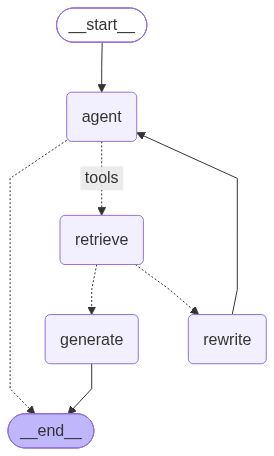

In [28]:
from IPython.display import Image, display

display(
    Image(
        graph.get_graph(xray=True).draw_mermaid_png()
    )
)

In [29]:
result = graph.invoke({
    "messages": [
        HumanMessage(content="What is LangGraph?")
    ]
})

print(result["messages"][-1].content)

---CALL AGENT---
---CHECK RELEVANCE---
---DECISION: DOCS NOT RELEVANT---
---TRANSFORM QUERY---
---CALL AGENT---
---CHECK RELEVANCE---
---DECISION: DOCS RELEVANT---
---GENERATE---
Based on the retrieved context, LangGraph is described as "our low-level orchestration framework" in the LangChain ecosystem. According to the documentation, LangGraph is specifically designed for "advanced needs combining deterministic and agentic workflows."

The context positions LangGraph as one of the key components in the LangChain ecosystem, distinct from other LangChain components like Deep Agents (which are "batteries-included" agents built on LangChain) and the LangChain (create_agent) approach for highly customizable agent harnesses.

LangGraph serves as a framework that works alongside LangChain for more complex use cases where deterministic and agentic workflows need to be combined at a lower level of abstraction than what's possible with the higher-level agent creation patterns. The context also 